# Lab 01: How to build a tool-calling agent

**CPU | API key: `OPENAI_API_KEY`**

## Goal

Build an agent from its parts: call a model, describe a tool, run the tool when the model asks for it, and loop until
the model answers. You write that loop by hand on OpenAI's Responses API, then rebuild it in a few lines with
LangChain's `create_agent`. Watch the reply when the model needs a shop policy: it is a request to run `get_policy`,
and nothing runs until your code runs it.

## What you will learn

- How to call a model with `client.responses.create` and read the reply's text and token usage.
- Why your code sends the whole conversation with every call.
- How to describe a tool to the model as a JSON schema.
- How to read a `function_call`, run the function and send back a `function_call_output`.
- How to write the agent loop, and how the model decides on each question whether to call a tool.
- How `@tool` and `create_agent` replace your schema and your loop, and what is still your job.

The lab makes about 20 calls to the chat model, a few thousand tokens in all: well under one US cent with
`gpt-4o-mini`.

## The first two cells

These are the same two cells that open Lab 00, which explains each line. **Setup** finds the repository folder (on
Colab it copies the repository and installs the packages first). **Config** reads the model names from `models.env`
and finds your key without printing it.

In [1]:
# Setup: on Colab, copy the repository and install the packages. Locally (after uv sync) nothing is installed.
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/agentic_ai_conversational_agents").exists():
        !git clone -q --depth 1 https://github.com/tatwan/agentic_ai_conversational_agents.git /content/agentic_ai_conversational_agents
    %cd /content/agentic_ai_conversational_agents
    %pip install -q -r requirements.txt

ROOT = next(folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "models.env").exists())
sys.path.insert(0, str(ROOT))
print("Repository folder:", ROOT.name)

Repository folder: agentic_ai_conversational_agents


⚠️ On Colab, run the setup cell first in a fresh session. If another cell loaded the old `openai` package before the
install, Part A or F fails with `ImportError: cannot import name ... from 'openai...'`; use **Runtime → Restart session**
and run from the top.

In [2]:
# Config: model names come from models.env; the key from the environment, .env or Colab Secrets.
from shared.settings import load_settings, load_key

settings = load_settings()
key_found_in = load_key("OPENAI_API_KEY")

for name in ("CHAT_MODEL", "REASONING_EFFORT", "JUDGE_MODEL", "EMBED_MODEL"):
    print(f"{name:18}{settings[name] or '(not set)'}")
print(f"{'OPENAI_API_KEY':18}{'found in ' + key_found_in if key_found_in else 'not found'}")

CHAT_MODEL        gpt-4o-mini
REASONING_EFFORT  (not set)
JUDGE_MODEL       gpt-4o-mini
EMBED_MODEL       text-embedding-3-small
OPENAI_API_KEY    found in .env


`CHAT_MODEL` is the model every call uses; to try another, change that one line in `models.env`. The outputs saved
here come from `gpt-4o-mini-2024-07-18` on 12 Oct 2026, and your replies will be worded differently.

The picture shows where the lab ends: one turn in which the model asks for a tool and your code runs it.

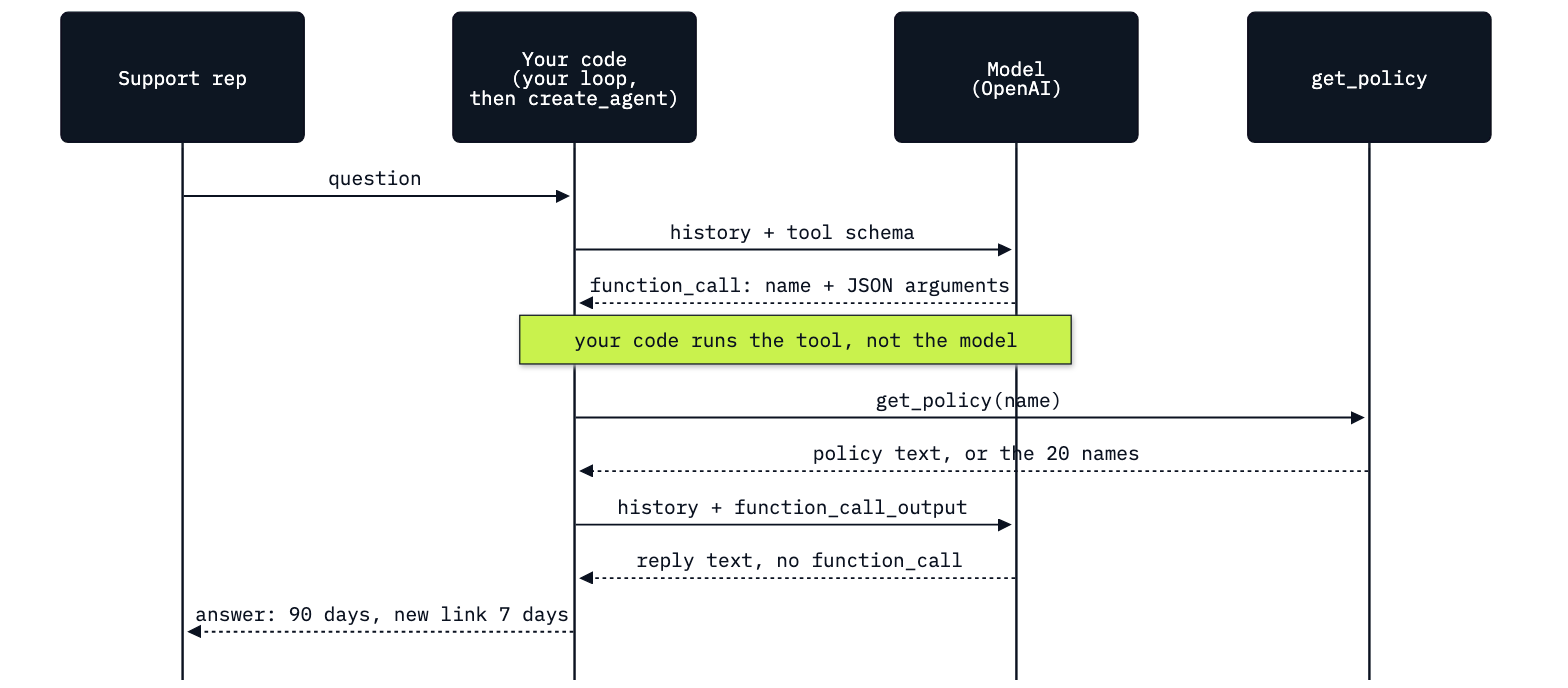

In [3]:
from IPython.display import Image
Image(filename=ROOT / "01_First_Chain_And_Tool" / "resources" / "lab01_tool_call.png", width=760)

---

## Part A: Call the model once

This part makes one call with OpenAI's own Python library and no framework, so you see exactly what goes to the
model and what comes back.

The [Responses API](https://developers.openai.com/api/docs/guides/migrate-to-responses) takes three arguments here:

- `model`: the model's name, read from `models.env`, so no model name is written in the code.
- `instructions`: the system prompt, your standing instructions for every reply.
- `input`: the conversation, a list of messages. Each message is a dictionary with a `role` (`user` for the rep)
  and its `content`.

There is no `temperature`: reasoning models reject it or ignore it, and the labs must run on whichever model
`models.env` names. `OpenAI()` finds your key in the environment, where the config cell put it.

The question is the one from Lab 00. Chinook's answer is in a policy file that this call does not include. Predict:
will the reply give Chinook's rule?

In [4]:
from openai import OpenAI

client = OpenAI()
SYSTEM = "You help Chinook support reps. Be brief."
question = "How long does a digital download link last?"

response = client.responses.create(
    model=settings["CHAT_MODEL"],
    instructions=SYSTEM,
    input=[{"role": "user", "content": question}],
)
print(response.output_text)

A digital download link typically lasts for 30 days from the purchase date, but it may vary depending on the seller's policy. Always check the specific terms provided.


`output_text` is the text of the reply. Next, the token counts, which are what you pay for, and the exact model that
answered.

In [5]:
usage = response.usage
print("model:        ", response.model)
print("input tokens: ", usage.input_tokens)
print("output tokens:", usage.output_tokens)
print("  reasoning:  ", usage.output_tokens_details.reasoning_tokens)

model:         gpt-4o-mini-2024-07-18
input tokens:  30
output tokens: 34
  reasoning:   0


Input tokens are everything you sent; output tokens are the reply. A reasoning model also writes hidden reasoning
tokens before it answers, billed as output though you never read them. `gpt-4o-mini` has no reasoning step, so that
line is 0.

Now read the policy the answer should have come from.

In [6]:
policy_file = ROOT / "data" / "corpus" / "policy_digital_downloads.md"
print(policy_file.read_text())

# Digital downloads

A digital album is available for download for 90 days after purchase. After that the link expires. The customer can request one new link; it lasts 7 days.

Downloads are tied to the customer email on the invoice. We do not send a second copy to a different email.

There is no return and no refund on a completed download unless the file is corrupt. Then we re-issue the link.



Chinook gives 90 days after purchase, and one new link that lasts 7 days. Our reply said *30 days from the purchase
date*; five more runs said 7 to 14 days, 7 to 30 days or 30 days, never 90. Nothing in the reply says it is a guess.
The model answered from what it learned in training, because the policy was not in the request. You catch a mistake
like this only by checking the answer against the source.

`output_text` is a shortcut. The response holds a list, `response.output`, of **output items**. Print their types.

In [7]:
for item in response.output:
    print(item.type)

message


One item, a `message`, which holds the text. Later in the lab this list holds other kinds of items, and your code
reads them to decide what to do next.

### Checkpoint A

| You should see | Our run |
|---|---|
| The reply | a period that is not Chinook's 90 days (ours: 30 days) |
| Token usage | about 30 input tokens, a few dozen output, 0 reasoning (ours: 30 input, 34 output) |
| `response.output` | one `message` item (a reasoning model adds a `reasoning` item) |

---

## Part B: Send the conversation with every call

This part shows that the model keeps nothing between calls, so your code has to hold the conversation.

Ask a follow-up on its own, as a new call. Predict: will the model know what *your last answer* is?

In [8]:
follow_up = "Put your last answer in one short sentence I can send to the customer."

alone = client.responses.create(
    model=settings["CHAT_MODEL"],
    instructions=SYSTEM,
    input=[{"role": "user", "content": follow_up}],
)
print(alone.output_text)

I can assist with your inquiry; please let me know your question.


Ours: *I can assist with your inquiry; please let me know your question.* The model saw only this one message, so it
had no earlier answer to shorten (nothing about download links in 3 of 3 runs). Every call starts from nothing.

To continue a conversation, send all of it again: the first question, the model's reply, then the follow-up. The
items in `response.output` can go straight back into the next `input`, so add them as they are.

In [9]:
history = [{"role": "user", "content": question}]
history += response.output
history.append({"role": "user", "content": follow_up})

second = client.responses.create(
    model=settings["CHAT_MODEL"],
    instructions=SYSTEM,
    input=history,
)
print(second.output_text)
print("input tokens:", second.usage.input_tokens)

A digital download link usually lasts for 30 days from the purchase date, but please check the specific terms for any variations.
input tokens: 86


Now the model shortens its own earlier answer, still with 30 days: the policy is not in the conversation yet. Input
tokens rose from 30 to 86, because each call pays again for everything before it.

The Responses API can also keep the conversation on OpenAI's side and continue it with `previous_response_id`. These
labs send the history themselves, so you can see and control what the model receives.

### Checkpoint B

| You should see | Our run |
|---|---|
| The follow-up alone | a reply that knows nothing about download links |
| With the history | a one-sentence version of the first answer; more input tokens (ours: 86) |

---

## Part C: Describe a tool to the model

This part gives the model a way to ask for the policy.

A **tool** is a function in your code that the model may ask you to run. The model never sees the code, only a
description: a name, what the tool does and when to use it, and a JSON schema for its arguments. When it wants the
tool, it replies with a **function call**, the tool's name and the arguments to use, and your code decides what
happens next.

First the function, in plain Python. `get_policy` returns the text of one policy file. For a name that does not exist
it returns the list of the 20 valid names instead of raising an error; Part E shows why.

In [10]:
CORPUS = ROOT / "data" / "corpus"
POLICIES = sorted(path.stem.removeprefix("policy_") for path in CORPUS.glob("policy_*.md"))


def get_policy(name: str) -> str:
    """Return the full text of one Chinook support policy.

    Call it before answering any question about shop rules.

    Args:
        name: Policy name, e.g. "refunds" or "escalations".
    """
    path = CORPUS / f"policy_{name}.md"
    if not path.exists():
        return f"No policy named {name!r}. Known: {', '.join(POLICIES)}."
    return path.read_text(encoding="utf-8")


print(get_policy("vip"))

No policy named 'vip'. Known: accounts, cancellations, damaged_media, data_retention, digital_downloads, escalations, exchanges, gift_cards, international, library, payment, preorders, privacy, refunds, returns, shipping, student_discount, support_hours, support_reps, warranty.


Now describe it. The dictionary below is a tool in OpenAI's
[function-calling format](https://developers.openai.com/api/docs/guides/function-calling) for the Responses API:

- `name`: what the model writes when it wants this tool.
- `description`: what the tool does and when to call it. The model decides from this text alone.
- `parameters`: a JSON schema for the arguments, here an object with one required string, `name`.
- `strict: True`: the model's arguments always match the schema. Strict mode needs `additionalProperties: False`,
  and OpenAI recommends it for every function.

The description repeats the docstring on purpose: in Part F, LangChain builds this dictionary from the docstring.

In [11]:
GET_POLICY_SCHEMA = {
    "type": "function",
    "name": "get_policy",
    "description": "Return the full text of one Chinook support policy. "
                   "Call it before answering any question about shop rules.",
    "parameters": {
        "type": "object",
        "properties": {
            "name": {"type": "string", "description": 'Policy name, e.g. "refunds" or "escalations".'},
        },
        "required": ["name"],
        "additionalProperties": False,
    },
    "strict": True,
}

Ask Part A's question again, with the tool in `tools` and instructions that tell the model to check the policy.
Predict: will the reply have any text?

In [12]:
SYSTEM = "You help Chinook support reps. Check the policy before you answer."
history = [{"role": "user", "content": question}]

response = client.responses.create(
    model=settings["CHAT_MODEL"],
    instructions=SYSTEM,
    input=history,
    tools=[GET_POLICY_SCHEMA],
)
print("output_text:", repr(response.output_text))
for item in response.output:
    print(item.type)

output_text: ''
function_call


No text. The output is a `function_call` item. Find it in the list and read its three fields.

In [13]:
call = next(item for item in response.output if item.type == "function_call")
print("name:     ", call.name)
print("arguments:", call.arguments)
print("call_id:  ", call.call_id)

name:      get_policy
arguments: {"name":"digital_downloads"}
call_id:   call_shwVQpurZ66JmsRvBa1BSiot


`name` is the tool the model wants, `arguments` is a JSON string that follows your schema, and `call_id` labels this
request so the result can be matched to it. In our run the model asked for
`{"name":"digital_downloads"}`, the exact file name. Often it does not: in five of six other runs its first guess was
a near miss such as `digital downloads`. Either way, nothing has run yet. The model has only asked.

The near miss is a reasonable guess. The model never sees the file names, only the two examples in your schema, and
both are one word, so nothing shows it that longer names use underscores. Part E shows the model correcting the name
from the list in your error text; the first challenge gives it the names up front and counts what that costs.

### Checkpoint C

| You should see | Our run |
|---|---|
| `get_policy("vip")` | `No policy named 'vip'. Known: accounts, cancellations, ...` with all 20 names |
| The reply with the tool | `output_text: ''` and one `function_call` item (a reasoning model adds a `reasoning` item first) |
| The call | `name` `get_policy`, `arguments` a JSON string with a `name` (ours: `{"name":"digital_downloads"}`) |

---

## Part D: Run the tool and send the result back

This part closes the loop: your code runs the function and gives the model its result.

`call.arguments` is a string, so `json.loads` turns it into a dictionary, and `**` passes the dictionary to the
function as keyword arguments.

In [14]:
import json

arguments = json.loads(call.arguments)
result = get_policy(**arguments)
print(arguments)
print(result[:200])

{'name': 'digital_downloads'}
# Digital downloads

A digital album is available for download for 90 days after purchase. After that the link expires. The customer can request one new link; it lasts 7 days.

Downloads are tied to t


Send the result back as a `function_call_output` item with the same `call_id`. Add the model's output to the history
first: the result must follow the call it answers. Predict: will the next reply be text or another call?

In [15]:
history += response.output
history.append({"type": "function_call_output", "call_id": call.call_id, "output": result})

response = client.responses.create(
    model=settings["CHAT_MODEL"],
    instructions=SYSTEM,
    input=history,
    tools=[GET_POLICY_SCHEMA],
)
print("output_text:", repr(response.output_text[:200]))
for item in response.output:
    print(item.type, getattr(item, "arguments", ""))

output_text: 'A digital album download link is available for **90 days** after purchase. If needed, customers can request a new link, which lasts for an additional **7 days**. Please note that downloads are tied to'
message 


In our run the second reply was the answer, a `message` with the policy's 90 days and 7 days, because the first name
was right. When the name is wrong, the tool returns the list of names, and the second reply is another
`function_call` with a corrected name. You cannot know in advance how many rounds a question needs, so the next step
is a loop.

The loop adds all of `response.output` to the history, not only the function call. A reasoning model returns a
`reasoning` item with its call, and OpenAI asks for it back with the result; on a model without reasoning the list
holds only the call, so the same code works on both.

In [16]:
model_calls = 2   # the two calls above

while any(item.type == "function_call" for item in response.output):
    history += response.output
    for item in response.output:
        if item.type == "function_call":
            result = get_policy(**json.loads(item.arguments))
            history.append({"type": "function_call_output", "call_id": item.call_id, "output": result})
    response = client.responses.create(
        model=settings["CHAT_MODEL"],
        instructions=SYSTEM,
        input=history,
        tools=[GET_POLICY_SCHEMA],
    )
    model_calls += 1

print(model_calls, "model calls")
print(response.output_text)

2 model calls
A digital album download link is available for **90 days** after purchase. If needed, customers can request a new link, which lasts for an additional **7 days**. Please note that downloads are tied to the customer’s email on the invoice, and there are no returns or refunds for completed downloads, unless the file is corrupt.


Those lines are the whole agent loop: call the model, run every function it asks for, send the results back, and stop
when a reply has no function call. With more than one tool, you would pick the function by `item.name`.

Our answer was already there, so the loop did not go round: 2 model calls. Over six runs the answer gave 90
days every time, after 2 model calls, or 3 when the first name was wrong (5 of 6). Part E shows such a run.

### Checkpoint D

| You should see | Our run |
|---|---|
| The tool's result | the policy, or the error text with the 20 names when the name was wrong |
| The reply after one round | the answer, or another `function_call` with a corrected name |
| After the loop | 90 days after purchase; one new link that lasts 7 days; 2 or 3 model calls (ours: 2) |

---

## Part E: Ask a question that needs no tool

This part shows the model choosing, question by question, whether to use the tool.

Each piece has now run on its own, so join them in one function, `ask`. It is Part D's loop with the first call
inside it; it returns the reply and the names of the policies it read.

In [17]:
def ask(question):
    history = [{"role": "user", "content": question}]
    policies_read = []
    while True:
        response = client.responses.create(
            model=settings["CHAT_MODEL"], instructions=SYSTEM, input=history, tools=[GET_POLICY_SCHEMA],
        )
        calls = [item for item in response.output if item.type == "function_call"]
        if not calls:
            return response.output_text, policies_read
        history += response.output
        for call in calls:
            arguments = json.loads(call.arguments)
            policies_read.append(arguments["name"])
            history.append({"type": "function_call_output", "call_id": call.call_id,
                            "output": get_policy(**arguments)})

Reps also ask for help with wording. Ask both kinds of question with the same instructions and the same tool. Predict:
will the model call `get_policy` for the second one?

In [18]:
polite = "Rewrite this more politely: 'We already told you, read the email.'"

for each in (question, polite):
    reply, policies_read = ask(each)
    print(each)
    print("  policies read:", policies_read)
    print("  reply:", reply[:150])

How long does a digital download link last?
  policies read: ['digital downloads', 'digital_downloads']
  reply: A digital album is available for download for **90 days** after purchase. After that, the link expires. Customers can request a new link, which will l


Rewrite this more politely: 'We already told you, read the email.'
  policies read: []
  reply: "We kindly ask you to please refer to the email we previously sent for the information. Thank you!"


For the download question the model read two policies: `digital downloads`, a name that does not exist, then
`digital_downloads`, taken from the list in your error text. That list is why `get_policy` returns text instead of
raising an error. For the rewrite it read none and answered at once, in all five of our runs.

Your code did not choose: it offered a tool and followed the replies. The model's choice, made while the program
runs, is what makes this an agent and not a fixed sequence of steps. It is also why an agent is tested on questions
that should use a tool and on questions that should not.

### Checkpoint E

| You should see | Our run |
|---|---|
| The download question | one or two policies read, the last one `digital_downloads`; 90 days in the reply |
| The rewrite | `policies read: []` and a politer sentence |

---

## Part F: Build the same agent with LangChain

This part replaces your schema and your loop with LangChain, so you can see what each piece became.

First the schema. LangChain's `tool` builds it from a function's name, type hints and docstring;
`parse_docstring=True` reads a Google-style docstring (a summary, then an `Args:` line per argument). You usually
write it as `@tool` above a function. Here it wraps the `get_policy` you already have, and `convert_to_openai_tool`
shows what LangChain will send, so you can compare it with your schema.

In [19]:
from langchain.tools import tool
from langchain_core.utils.function_calling import convert_to_openai_tool

policy_tool = tool(get_policy, parse_docstring=True)
built = convert_to_openai_tool(policy_tool)["function"]

for field in ("name", "description", "parameters"):
    print(field)
    print("  yours: ", json.dumps(GET_POLICY_SCHEMA[field]))
    print("  @tool: ", json.dumps(built[field]))

name
  yours:  "get_policy"
  @tool:  "get_policy"
description
  yours:  "Return the full text of one Chinook support policy. Call it before answering any question about shop rules."
  @tool:  "Return the full text of one Chinook support policy. Call it before answering any question about shop rules."
parameters
  yours:  {"type": "object", "properties": {"name": {"type": "string", "description": "Policy name, e.g. \"refunds\" or \"escalations\"."}}, "required": ["name"], "additionalProperties": false}
  @tool:  {"properties": {"name": {"description": "Policy name, e.g. \"refunds\" or \"escalations\".", "type": "string"}}, "required": ["name"], "type": "object"}


The name, the description and the one required string `name` match yours: LangChain took them from the function's
name, docstring and type hint. `additionalProperties` and `strict` are missing. When `strict` is left out, the
Responses API tries strict mode on its own and falls back to best effort if the schema does not allow it. From now on
the docstring is the description the model reads.

Next the model. `ChatOpenAI` from `langchain-openai` wraps the same OpenAI client.

- `use_responses_api=True` sends requests through the Responses API, like your calls. Without it, `langchain-openai`
  picks the API itself, and a plain `gpt-4o-mini` call goes through the older Chat Completions API.
- `reasoning_effort` passes `REASONING_EFFORT` from `models.env`. It is empty for a model without reasoning, and
  `None` sends nothing.

Later labs build this same object with `shared.settings.chat_model()`.

In [20]:
from langchain_openai import ChatOpenAI

model = ChatOpenAI(
    model=settings["CHAT_MODEL"],
    use_responses_api=True,
    reasoning_effort=settings["REASONING_EFFORT"] or None,
)

`create_agent` takes the model, the tools and the instructions, and runs the loop you wrote in Part D. `invoke` takes
the conversation's messages and returns them with every message the run added. Print each one: its type, then its
tool calls or the start of its text.

In [21]:
from langchain.agents import create_agent

agent = create_agent(model, tools=[policy_tool], system_prompt=SYSTEM)

result = agent.invoke({"messages": [{"role": "user", "content": question}]})
for message in result["messages"]:
    tool_calls = [call["args"] for call in getattr(message, "tool_calls", [])]
    print(f"{message.type:5} |", tool_calls or message.text[:100].replace("\n", " "))

human | How long does a digital download link last?
ai    | [{'name': 'digital_downloads'}]
tool  | # Digital downloads  A digital album is available for download for 90 days after purchase. After tha
ai    | A digital album is available for download for 90 days after purchase. After that, the link expires. 


Each message matches a step of your loop. `human` is the question. An `ai` message with a tool call held a
`function_call`, its arguments already a dictionary. A `tool` message is a `function_call_output`: the agent ran
`get_policy` in your Python process, as your loop did. The last `ai` message is the answer. Ours named
`digital_downloads` at once: four messages, two model calls.

Now the rewrite through the agent.

In [22]:
result = agent.invoke({"messages": [{"role": "user", "content": polite}]})
print(len(result["messages"]), "messages")
print(result["messages"][-1].text)

2 messages
"Thank you for your message. We kindly recommend referring to the email we previously sent for the information you need."


Two messages, the question and the answer: one model call and no tool, as in Part E.

### What LangChain does for you, and what is still yours

| In your loop | With LangChain |
|---|---|
| The JSON schema, written by hand | `tool` builds it from the name, the type hints and the docstring |
| `json.loads(item.arguments)` | `tool_calls` on the `ai` message, arguments already a dictionary |
| Run the function, append a `function_call_output` with its `call_id` | the agent's tool step adds a `tool` message |
| `while` a reply has a function call | the agent loops until a reply has no tool call |
| The `history` list | the `messages` in the result |

Still yours:

- What the tool does, and what it returns when the arguments are wrong: the list of names let the model recover.
- The description and the instructions: the model chose whether to call the tool, and which name to send, from
  those alone.
- Checking the answer against its source, as in Part A.
- A limit on the loop: neither loop stops a model that keeps asking for tools (challenge task 2).
- The conversation across turns: each `invoke` starts from the messages you pass, like Part B's single call. Lab 03
  keeps a thread.

### Checkpoint F

| You should see | Our run |
|---|---|
| The two schemas | the same name, description and `name` argument; no `strict` or `additionalProperties` in `@tool`'s |
| The agent's run | `human`, then pairs of `ai` (tool call) and `tool`, then the answer with 90 days and 7 days (ours: 4 messages, 2 model calls) |
| The rewrite | 2 messages |

## What you can do now

- Call a model with `client.responses.create` and read `output_text`, `usage` and the items in `response.output`.
- Keep a conversation yourself: send the history with every call, adding each response's output.
- Describe a function as a tool: a name, a description that says when to call it, and a strict JSON schema.
- Read a `function_call`, run the function with `json.loads` and `**`, and send back a `function_call_output` with
  its `call_id`.
- Write the loop that runs until a reply has no function call, and test it on a question that needs a tool and one
  that does not.
- Build the same agent with `tool` and `create_agent`, and say which parts LangChain took over and which are still
  yours.

## Troubleshooting

| Symptom | Likely cause | Fix |
|---|---|---|
| Status 400, `No tool output found for function call call_...` | a `function_call` in the history has no `function_call_output` | append one output per call, as the loop does |
| Status 400, `No tool call found for function call output with call_id call_...` | the result was sent without the call before it | add `response.output` to the history first |
| Status 400, `Invalid schema for function 'get_policy': ... 'additionalProperties' is required to be supplied and to be false.` | `strict: True` without `"additionalProperties": False` | add it to `parameters` |
| `TypeError: ... argument after ** must be a mapping, not str` | `call.arguments` used without `json.loads` | `get_policy(**json.loads(call.arguments))` |
| `ValueError: Found invalid Google-Style docstring.` | the docstring has no `Args:` section | add an `Args:` line named like the parameter |
| `AuthenticationError` or `Missing credentials` | no key, or a wrong one | Lab 00's troubleshooting table, then the config cell again |
| Replies, names or counts differ from ours | replies change from run to run | check the facts (90 days, 7 days) and the shape of the run |

## Challenge

Use the pieces from Part F. A worked solution is in `solved/` for the instructor.

1. **Put the names in the description.** Write `get_policy_listed`, a copy of `get_policy` whose `Args:` line lists
   the 20 policy names, and build an agent with it. Run the download question three times and count the model calls.
   Expected: two calls every time, since the model reads the exact name; each call's input tokens are higher,
   because the longer description goes with every call. Say when this trade stops being worth it.
2. **Cap the loop.** Rebuild the agent with `middleware=[ModelCallLimitMiddleware(run_limit=1)]` (from
   `langchain.agents.middleware`) and run the download question. Expected: the run stops after one model call; the
   last message reads *Model call limits exceeded: run limit (1/1)* and has no token usage, because the middleware
   wrote it. Then choose a limit that lets a run with one wrong policy name finish.
3. **Check the source, not only the answer.** Ask the agent: *A customer's vinyl arrived warped, and it is the second
   time for the same title. What should the rep offer?* Print the run's messages as in Part F: which policy holds the
   rule, which one did the model read, and does what it read support its answer? Ask task 1's agent too. Expected:
   the rule is in `policy_damaged_media.md` (*offer a refund instead of a third copy*). In our runs the
   agent read `refunds` in 6 of 6 and still said "refund", a conclusion the refunds policy does not contain, so the
   answer was right by luck. Task 1's agent read `damaged_media` in 4 of 5; once it read `exchanges`
   and offered an exchange, which is wrong for a second damaged copy.

## Resources

- [OpenAI: function calling](https://developers.openai.com/api/docs/guides/function-calling): tools, `function_call`, `function_call_output`, strict mode, reasoning items
- [OpenAI: migrate to the Responses API](https://developers.openai.com/api/docs/guides/migrate-to-responses): `instructions`, `input`, output items, `previous_response_id`
- [OpenAI: reasoning models](https://developers.openai.com/api/docs/guides/reasoning): reasoning tokens and effort, on the models that have them
- [LangChain: tools](https://docs.langchain.com/oss/python/langchain/tools) and [agents](https://docs.langchain.com/oss/python/langchain/agents): `@tool` and `create_agent`
- [LangChain: `ChatOpenAI`](https://docs.langchain.com/oss/python/integrations/chat/openai): `use_responses_api`, `reasoning_effort`
- [LangChain: built-in middleware](https://docs.langchain.com/oss/python/langchain/middleware/built-in): the model call limit in task 2

Next: [Lab 02: How to write a dialogue prompt and test it](../02_Dialogue_Prompt_Versions/README.md).